# FMR of a synthetic antiferromagnet in a rotating field (polar sweep)

This example uses `DoubleLayerNumeric` with the external field rotated from the film normal to the film plane ("polar sweep", as in out-of-plane angle-resolved FMR).  For each field direction, the equilibrium directions of both magnetizations (which tilt out of the plane) are found by `GetEquilibrium()`, and the uniform-mode ($k \to 0$) frequencies of the two modes follow from `GetDispersion()`.  Note that `GetDispersion()` sorts the modes by frequency: in the antiparallel or scissors states the lower mode is the acoustic one (in-phase precession of the two layers), but in the saturated (parallel) state of an antiferromagnetically coupled bilayer the *optical* mode (antiphase precession) has the lower frequency.  The character of each mode can be read from the eigenvectors, as done below.  At the end, the resonance fields at a fixed frequency are calculated for comparison with the measurement of [Gallardo *et al.*, *Phys. Rev. Applied* **12**, 034012 (2019)](https://doi.org/10.1103/PhysRevApplied.12.034012), Supplemental Material Fig. S1.

The system is their Py(6.7 nm)/Ir(0.6 nm)/CoFeB(5.7 nm) bilayer with the parameters of their Table I.  The table gives the effective magnetizations $\mu_0 M_\mathrm{eff} = \mu_0 M_s - 2 K_s/M_s$ (i.e. the perpendicular anisotropies $K_s$ reduce the demagnetizing field) and the in-plane anisotropy field of Py, but not the saturation magnetizations and gyromagnetic ratios, which are assumed below (typical values; a different gyromagnetic ratio of each layer is supported, `gamma` of each `Material`).

> **Frame of reference:** the polar angles (`theta` of the field, `thetaInit1`, `thetaInit2` and the equilibrium angles) are measured from the film normal, which points from layer 1 (bottom, here Py) to layer 2 (top, CoFeB); the in-plane angles are measured from the in-plane projection of the field, see the class documentation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
import SpinWaveToolkit as SWT

In [2]:
# --- Gallardo et al. 2019, Table I
# (Py = layer 1 at the bottom, CoFeB = layer 2 on top)
d1, d2, s = 6.7e-9, 5.7e-9, 0.6e-9  # (m) Py, CoFeB and Ir spacer thicknesses
Meff1, Meff2 = 942.5e-3/SWT.MU0, 1442.9e-3/SWT.MU0  # (A/m) effective magn.
Bu1 = 4.0e-3  # (T) in-plane uniaxial anisotropy field of Py (CoFeB: none)
Jbl, Jbq = -0.195e-3, -0.044e-3  # (J/m^2) bilinear and biquadratic coupling

# --- assumed (not given in the paper)
Ms1, Ms2 = 800e3, 1250e3  # (A/m) saturation magnetizations of Py and CoFeB
gamma1, gamma2 = 29.4*2e9*np.pi, 29.0*2e9*np.pi  # (rad/s/T) g = 2.10, 2.07
Py = SWT.Material(Ms=Ms1, Aex=13e-12, alpha=0.008, gamma=gamma1)
CoFeB = SWT.Material(Ms=Ms2, Aex=15e-12, alpha=0.005, gamma=gamma2)

# perpendicular anisotropies from the effective magnetizations,
# M_eff = Ms - 2*Ks/(MU0*Ms)
Ks1 = (Ms1 - Meff1)*SWT.MU0*Ms1/2
Ks2 = (Ms2 - Meff2)*SWT.MU0*Ms2/2
# (J/m^3) in-plane anisotropy of Py, easy axis along the in-plane field
Ku1 = Bu1*Ms1/2
print(f"Ks1 = {Ks1/1e3:.1f} kJ/m^3, Ks2 = {Ks2/1e3:.1f} kJ/m^3, "
      f"Ku1 = {Ku1:.0f} J/m^3")

# small k for the uniform mode; the field in-plane and perpendicular to k
# (its in-plane angle is irrelevant for k -> 0), rotated in the sweeps below
saf = SWT.DoubleLayerNumeric(
    Bext=0.3, material=Py, d=d1, kxi=np.array([1e3]),
    theta=np.pi/2, phi=np.pi/2, Jbl=Jbl, Jbq=Jbq, s=s, d2=d2, material2=CoFeB,
    Ku=Ku1, Ku2=0, Ks1=Ks1, Ks2=Ks2,
)

Ks1 = 25.1 kJ/m^3, Ks2 = 79.9 kJ/m^3, Ku1 = 1600 J/m^3


## Equilibrium and FMR frequencies in a rotating field

The field of fixed magnitude is rotated from the normal ($\theta_H = 0$) to the plane ($\theta_H = 90°$).  At each angle, the minimization starts from the equilibrium of the previous angle (`thetaInit`, `phiInit` are updated), so that the magnetization follows its branch continuously.  At high fields, both layers are nearly parallel to the field; at lower fields and in-plane directions, the antiferromagnetic coupling opens the scissors state, visible as a splitting of the two polar angles.

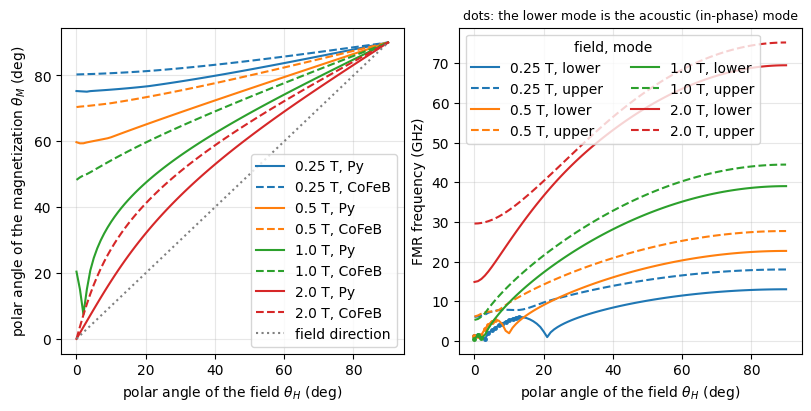

In [3]:
def set_start(saf, angles):
    """Use `angles` = (theta1, phi1, theta2, phi2) as the initial guess
    of the equilibrium search."""
    saf.thetaInit1, saf.phiInit1, saf.thetaInit2, saf.phiInit2 = angles


def polar_sweep(saf, Bext, thetas_H):
    """Equilibrium angles (4, N), uniform-mode frequencies (2, N) and
    the character of the lower mode (N) for a field of magnitude `Bext`
    at the polar angles `thetas_H`, following the equilibrium from one
    angle to the next."""
    saf.Bext = Bext
    set_start(saf, (thetas_H[0], 0.0, thetas_H[0], 0.0))  # along the field
    angles = np.zeros((4, len(thetas_H)))
    freqs = np.zeros((2, len(thetas_H)))
    in_phase = np.zeros(len(thetas_H))
    for i, th in enumerate(thetas_H):
        saf.theta = th
        angles[:, i] = saf.GetEquilibrium()
        w, v = saf.GetDispersion(angles=angles[:, i])
        freqs[:, i] = w[:, 0]/(2e9*np.pi)
        # in-phase (acoustic, +1) or antiphase (optical, -1) precession of
        # the two layers from the in-plane amplitudes (eigenvector
        # components 0 and 2) of the lower mode
        in_phase[i] = np.sign(np.real(v[0, 0, 0]*np.conj(v[2, 0, 0])))
        set_start(saf, angles[:, i])
    return angles, freqs, in_phase


# (small offset: off the symmetric directions)
thetas_H = np.deg2rad(np.linspace(0, 90, 91) + 1e-3)
fields = (0.25, 0.5, 1.0, 2.0)  # (T)
results = {B: polar_sweep(saf, B, thetas_H) for B in fields}

deg_H = np.degrees(thetas_H)
fig, axs = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
for B, (angles, freqs, in_phase) in results.items():
    l, = axs[0].plot(deg_H, np.degrees(angles[0]), label=f"{B} T, Py")
    c = l.get_color()
    axs[0].plot(deg_H, np.degrees(angles[2]), "--", color=c,
                label=f"{B} T, CoFeB")
    axs[1].plot(deg_H, freqs[0], color=c, label=f"{B} T, lower")
    axs[1].plot(deg_H, freqs[1], "--", color=c, label=f"{B} T, upper")
    # mark where the lower mode is the acoustic (in-phase) one
    ac = in_phase > 0
    axs[1].plot(deg_H[ac], freqs[0, ac], ".", color=c, ms=5)
axs[0].plot(deg_H, deg_H, ":", color="gray", label="field direction")
axs[0].set_xlabel(r"polar angle of the field $\theta_H$ (deg)")
axs[0].set_ylabel(r"polar angle of the magnetization $\theta_M$ (deg)")
axs[0].legend(ncol=1)
axs[1].set_xlabel(r"polar angle of the field $\theta_H$ (deg)")
axs[1].set_ylabel("FMR frequency (GHz)")
axs[1].set_title("dots: the lower mode is the acoustic (in-phase) mode",
                 fontsize=9)
axs[1].legend(ncol=2, title="field, mode")
for ax in axs:
    ax.grid(alpha=0.3)
plt.show()

At 0.25 T, the in-plane field is above the saturation field of the bilayer, but the out-of-plane field is far below the saturation along the normal ($\sim \mu_0 M_\mathrm{eff}$), so the magnetizations are strongly tilted from the field for small $\theta_H$.  In the saturated parallel state (large fields), the lower mode is the optic one and the upper mode the acoustic one (no dots); the two modes exchange their character where the branches cross or anticross, which also appears in the measured resonance fields as an avoided crossing around $\theta_H \approx 10°$.

## Resonance field at fixed frequency

Angle-resolved FMR measures the resonance field at a fixed frequency.  For each field direction, we scan the field magnitude from high to low values (following the equilibrium) until the frequency of the mode crosses the excitation frequency, and refine the crossing with a root search.  The frequency of each mode is a smooth function of the field, but the equilibrium can switch between branches at low fields, which is why the scan starts from the saturated state. Note that the naming *lower* and *upper* mode here still refers to the position in frequency at fixed field.

In [4]:
def resonance_fields(saf, f_target, thetas_H, B_max=3.0, B_min=0.05, nB=60):
    """Resonance fields (2, N) of the lower and upper modes at the
    frequency `f_target` (GHz) for the polar field angles `thetas_H`:
    the largest field in [B_min, B_max] at which the mode frequency
    equals `f_target` (NaN if there is none)."""
    B_scan = np.linspace(B_max, B_min, nB)
    dB = B_scan[0] - B_scan[1]
    B_res = np.full((2, len(thetas_H)), np.nan)
    for i, th in enumerate(thetas_H):
        saf.theta = th
        set_start(saf, (th, 0.0, th, 0.0))

        def freq(B, mode, start=None):
            saf.Bext = B
            if start is not None:
                set_start(saf, start)
            angles = saf.GetEquilibrium()
            set_start(saf, angles)
            f = saf.GetDispersion(angles=angles)[0][mode, 0]/(2e9*np.pi)
            return f - f_target, angles

        f_prev = [freq(B_scan[0], m)[0] for m in (0, 1)]
        start = [saf.GetEquilibrium()]*2
        found = [False, False]
        for B in B_scan[1:]:
            for m in (0, 1):
                if found[m]:
                    continue
                f_now, angles = freq(B, m, start[m])
                if f_now*f_prev[m] < 0:  # crossing since the previous field
                    B_res[m, i] = brentq(lambda b: freq(b, m, start[m])[0],
                                         B, B + dB, xtol=1e-5)
                    found[m] = True
                f_prev[m], start[m] = f_now, angles
    return B_res


thetas_res = np.deg2rad(np.linspace(-20, 120, 100) + 1e-3)
deg_res = np.degrees(thetas_res)
B_res = resonance_fields(saf, 15.0, thetas_res)

# values read from Fig. S1 of Gallardo et al. (acoustic: black, optical: red
# symbols); at these fields the bilayer is saturated, so the lower-frequency
# mode (larger resonance field) is the optical one
ref = {0: (1.52, 1.97), 90: (0.19, 0.31)}
for th, (b_ac, b_op) in ref.items():
    i = np.argmin(abs(deg_res - th))
    print(f"theta_H = {th:2d} deg:")
    print(f"  upper mode: {B_res[1, i]:.3f} T (measured ~{b_ac} T)")
    print(f"  lower mode: {B_res[0, i]:.3f} T (measured ~{b_op} T)")

theta_H =  0 deg:
  upper mode: 1.502 T (measured ~1.52 T)
  lower mode: 2.004 T (measured ~1.97 T)
theta_H = 90 deg:
  upper mode: 0.183 T (measured ~0.19 T)
  lower mode: 0.295 T (measured ~0.31 T)


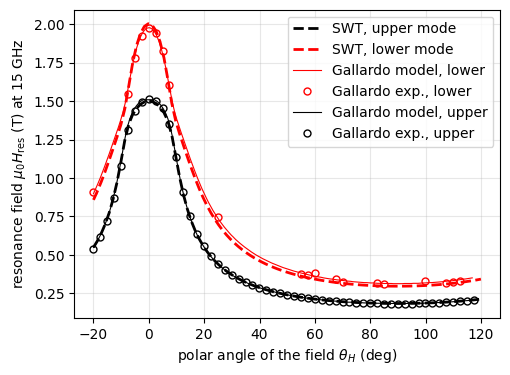

In [5]:
# load data from Gallardo et al. (2019) Fig. S1 and compare with SWT
S1data = np.loadtxt("static_data/SAF_Gallardo2019_FigS1.txt",
                      dtype=float, delimiter=";")

plt.figure(figsize=(5.5, 4))
plt.plot(deg_res, B_res[1], "k--", lw=2, label="SWT, upper mode")
plt.plot(deg_res, B_res[0], "r--", lw=2, label="SWT, lower mode")
expkw = dict(ms=5, mfc="none")  # marker style for the experimental data
plt.plot(S1data[:, 0], S1data[:, 1], "-r", label="Gallardo model, lower", lw=.8)
plt.plot(S1data[:, 2], S1data[:, 3], "or", **expkw,
         label="Gallardo exp., lower")
plt.plot(S1data[:, 4], S1data[:, 5], "-k", label="Gallardo model, upper", lw=.8)
plt.plot(S1data[:, 6], S1data[:, 7], "ok", **expkw,
         label="Gallardo exp., upper")

plt.xlabel(r"polar angle of the field $\theta_H$ (deg)")
plt.ylabel(r"resonance field $\mu_0 H_\mathrm{res}$ (T) at 15 GHz")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

The curves reproduce the measured and modelled dependences of Gallardo et al. (Fig. S1 of the Supplemental Material) within a few percent: the resonance fields of 1.5 T (acoustic) and 2.0 T (optic) along the normal, their fast decrease with the angle, and the in-plane values of 0.19 T and 0.31 T.  The remaining differences come from the assumed saturation magnetizations and gyromagnetic ratios (which enter the interlayer coupling fields $J/(\mu_0 M_s d)$ and the frequency scale) and from the uniform-mode approximation of the model.

> **Note:** `resonance_fields()` follows the frequency order of the modes, not their character.  Where the two branches cross (around 10°), the frequency-sorted modes exchange their acoustic/optic character, which appears as the avoided crossing of the resonance fields in the measurement (where the modes couple weakly, e.g. due to inhomogeneities).